<a href="https://colab.research.google.com/github/Shahinur-22/PneuVision/blob/main/notebooks/PneuVision_Main.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import torch

print("PyTorch Version:", torch.__version__)

if torch.cuda.is_available():
    print("GPU Available:", torch.cuda.get_device_name(0))
else:
    print("GPU Not Available")


PyTorch Version: 2.11.0+cu130
GPU Available: Tesla T4


In [2]:
!pip install kaggle

In [7]:
import os

os.environ["KAGGLE_API_TOKEN"] = "KGAT_65f99d55ea92a809356093b6cac03262"

In [8]:
import os

print(os.environ.get("KAGGLE_API_TOKEN"))

KGAT_65f99d55ea92a809356093b6cac03262


In [9]:
!kaggle --version

Kaggle CLI 2.0.2


In [10]:
!kaggle datasets list -s chest-xray-pneumonia

ref                                                             title                                                      size  lastUpdated                 downloadCount  voteCount  usabilityRating  
--------------------------------------------------------------  --------------------------------------------------  -----------  --------------------------  -------------  ---------  ---------------  
divyam6969/chest-xray-pneumonia-dataset                         Chest XRAY - Pneumonia Dataset                       1151535496  2024-01-17 12:19:16.570000           1550         30  0.6875           
kostasdiamantaras/chest-xrays-bacterial-viral-pneumonia-normal  Chest Xrays: bacterial / viral pneumonia / normal    1222999548  2020-10-27 16:51:15.783000           6306         22  0.7058824        
amanullahasraf/covid19-pneumonia-normal-chest-xray-pa-dataset   COVID19_Pneumonia_Normal_Chest_Xray_PA_Dataset       2053474983  2020-07-13 05:54:22.483000           4433         36  0.8125       

In [11]:
!kaggle datasets download -d paultimothymooney/chest-xray-pneumonia

Dataset URL: https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia
License(s): other
100% 2.29G/2.29G [00:21<00:00, 113MB/s]



In [12]:
import zipfile
import os

zip_path = "chest-xray-pneumonia.zip"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall()

print("Dataset extracted successfully")

Dataset extracted successfully


In [13]:
import os

for root, dirs, files in os.walk("chest_xray"):
    level = root.count(os.sep)
    if level <= 2:
        print(root, "|", len(files), "files")

chest_xray | 0 files
chest_xray/train | 0 files
chest_xray/train/PNEUMONIA | 3875 files
chest_xray/train/NORMAL | 1341 files
chest_xray/__MACOSX | 1 files
chest_xray/__MACOSX/chest_xray | 3 files
chest_xray/val | 0 files
chest_xray/val/PNEUMONIA | 8 files
chest_xray/val/NORMAL | 8 files
chest_xray/chest_xray | 1 files
chest_xray/chest_xray/train | 1 files
chest_xray/chest_xray/val | 1 files
chest_xray/chest_xray/test | 1 files
chest_xray/test | 0 files
chest_xray/test/PNEUMONIA | 390 files
chest_xray/test/NORMAL | 234 files


In [14]:
import os

base_path = "chest_xray"

classes = ["NORMAL", "PNEUMONIA"]

for split in ["train", "test", "val"]:
    print("\n", split.upper())
    for cls in classes:
        path = os.path.join(base_path, split, cls)
        print(cls, ":", len(os.listdir(path)))


 TRAIN
NORMAL : 1341
PNEUMONIA : 3875

 TEST
NORMAL : 234
PNEUMONIA : 390

 VAL
NORMAL : 8
PNEUMONIA : 8


In [15]:
import os
import shutil
from sklearn.model_selection import train_test_split

original_train = "chest_xray/train"
new_base = "chest_xray_fixed"

classes = ["NORMAL", "PNEUMONIA"]

for split in ["train", "val", "test"]:
    for cls in classes:
        os.makedirs(
            os.path.join(new_base, split, cls),
            exist_ok=True
        )

for cls in classes:
    source = os.path.join(original_train, cls)

    images = os.listdir(source)

    train_imgs, val_imgs = train_test_split(
        images,
        test_size=0.15,
        random_state=42
    )

    for img in train_imgs:
        shutil.copy(
            os.path.join(source, img),
            os.path.join(new_base, "train", cls, img)
        )

    for img in val_imgs:
        shutil.copy(
            os.path.join(source, img),
            os.path.join(new_base, "val", cls, img)
        )

# Copy original test set
for cls in classes:
    source = os.path.join("chest_xray/test", cls)
    destination = os.path.join(new_base, "test", cls)

    for img in os.listdir(source):
        shutil.copy(
            os.path.join(source, img),
            os.path.join(destination, img)
        )

print("New dataset split created successfully")

New dataset split created successfully


In [16]:
import os

base_path = "chest_xray"

classes = ["NORMAL", "PNEUMONIA"]

for split in ["train", "test", "val"]:
    print("\n", split.upper())
    for cls in classes:
        path = os.path.join(base_path, split, cls)
        print(cls, ":", len(os.listdir(path)))


 TRAIN
NORMAL : 1341
PNEUMONIA : 3875

 TEST
NORMAL : 234
PNEUMONIA : 390

 VAL
NORMAL : 8
PNEUMONIA : 8


In [17]:
import os

base_path = "chest_xray_fixed"

classes = ["NORMAL", "PNEUMONIA"]

for split in ["train", "val", "test"]:
    print("\n", split.upper())
    for cls in classes:
        path = os.path.join(base_path, split, cls)
        print(cls, ":", len(os.listdir(path)))


 TRAIN
NORMAL : 1139
PNEUMONIA : 3293

 VAL
NORMAL : 202
PNEUMONIA : 582

 TEST
NORMAL : 234
PNEUMONIA : 390


In [18]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

In [19]:
train_transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.RandomRotation(10),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485,0.456,0.406],
        std=[0.229,0.224,0.225]
    )
])


val_transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485,0.456,0.406],
        std=[0.229,0.224,0.225]
    )
])

In [20]:
data_dir = "chest_xray_fixed"

train_dataset = datasets.ImageFolder(
    root=f"{data_dir}/train",
    transform=train_transform
)

val_dataset = datasets.ImageFolder(
    root=f"{data_dir}/val",
    transform=val_transform
)

test_dataset = datasets.ImageFolder(
    root=f"{data_dir}/test",
    transform=val_transform
)

print("Classes:", train_dataset.classes)
print("Train images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Test images:", len(test_dataset))

Classes: ['NORMAL', 'PNEUMONIA']
Train images: 4432
Validation images: 784
Test images: 624


In [21]:
batch_size = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Train batches: 139
Validation batches: 25
Test batches: 20


In [22]:
import torch.nn as nn
from torchvision import models

In [23]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = models.resnet18(weights="DEFAULT")

# Replace final layer
model.fc = nn.Linear(
    model.fc.in_features,
    2
)

model = model.to(device)

print(model)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 144MB/s]


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

In [24]:
import torch

class_counts = torch.tensor([
    1139,
    3293
])

weights = 1.0 / class_counts

weights = weights / weights.sum()

weights = weights.to(device)

print(weights)

tensor([0.7430, 0.2570], device='cuda:0')


In [25]:
criterion = nn.CrossEntropyLoss(
    weight=weights
)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.0001
)

print("Loss and optimizer ready")

Loss and optimizer ready


In [26]:
from tqdm import tqdm

epochs = 5

train_losses = []
val_losses = []

train_accs = []
val_accs = []


for epoch in range(epochs):

    print(f"\nEpoch {epoch+1}/{epochs}")

    # Training
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in tqdm(train_loader):

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()


        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()


    train_loss = running_loss / len(train_loader)
    train_accuracy = 100 * correct / total


    # Validation
    model.eval()

    val_loss = 0.0
    correct = 0
    total = 0


    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            val_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()


    val_loss = val_loss / len(val_loader)
    val_accuracy = 100 * correct / total


    train_losses.append(train_loss)
    val_losses.append(val_loss)

    train_accs.append(train_accuracy)
    val_accs.append(val_accuracy)


    print(f"Train Loss: {train_loss:.4f}")
    print(f"Train Accuracy: {train_accuracy:.2f}%")
    print(f"Val Loss: {val_loss:.4f}")
    print(f"Val Accuracy: {val_accuracy:.2f}%")


Epoch 1/5


100%|██████████| 139/139 [01:24<00:00,  1.65it/s]


Train Loss: 0.1193
Train Accuracy: 95.24%
Val Loss: 0.1752
Val Accuracy: 94.52%

Epoch 2/5


100%|██████████| 139/139 [01:20<00:00,  1.73it/s]


Train Loss: 0.0803
Train Accuracy: 96.91%
Val Loss: 0.0630
Val Accuracy: 97.07%

Epoch 3/5


...

Train Loss: 0.0449
Train Accuracy: 98.29%
Val Loss: 0.0602
Val Accuracy: 97.70%

Epoch 4/5


100%|██████████| 139/139 [01:19<00:00,  1.75it/s]


Train Loss: 0.0319
Train Accuracy: 98.69%
Val Loss: 0.0442
Val Accuracy: 98.72%

Epoch 5/5


100%|██████████| 139/139 [01:22<00:00,  1.69it/s]


Train Loss: 0.0486
Train Accuracy: 98.42%
Val Loss: 0.0654
Val Accuracy: 98.09%


In [27]:
torch.save(
    model.state_dict(),
    "resnet18_pneumonia_best.pth"
)

print("Model saved successfully")

Model saved successfully


In [28]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score
)

import numpy as np


model.eval()

all_labels = []
all_preds = []
all_probs = []


with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        probabilities = torch.softmax(outputs, dim=1)

        _, predicted = torch.max(outputs, 1)


        all_labels.extend(labels.cpu().numpy())
        all_preds.extend(predicted.cpu().numpy())
        all_probs.extend(
            probabilities[:,1].cpu().numpy()
        )


accuracy = accuracy_score(
    all_labels,
    all_preds
)

precision = precision_score(
    all_labels,
    all_preds
)

recall = recall_score(
    all_labels,
    all_preds
)

f1 = f1_score(
    all_labels,
    all_preds
)

auc = roc_auc_score(
    all_labels,
    all_probs
)


cm = confusion_matrix(
    all_labels,
    all_preds
)

TN, FP, FN, TP = cm.ravel()

specificity = TN / (TN + FP)


print("Accuracy:", round(accuracy*100,2), "%")
print("Precision:", round(precision*100,2), "%")
print("Recall:", round(recall*100,2), "%")
print("Specificity:", round(specificity*100,2), "%")
print("F1-score:", round(f1*100,2), "%")
print("ROC-AUC:", round(auc,4))

print("\nConfusion Matrix:")
print(cm)

Accuracy: 82.37 %
Precision: 78.0 %
Recall: 100.0 %
Specificity: 52.99 %
F1-score: 87.64 %
ROC-AUC: 0.9692

Confusion Matrix:
[[124 110]
 [  0 390]]


In [29]:
from torchvision import models
import torch.nn as nn

densenet_model = models.densenet121(
    weights="DEFAULT"
)

# Replace classifier
densenet_model.classifier = nn.Linear(
    densenet_model.classifier.in_features,
    2
)

densenet_model = densenet_model.to(device)

print("DenseNet121 ready")

Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 78.0MB/s]


DenseNet121 ready


In [30]:
criterion = nn.CrossEntropyLoss(
    weight=weights
)

optimizer = torch.optim.Adam(
    densenet_model.parameters(),
    lr=0.0001
)

print("Optimizer ready")

Optimizer ready


In [31]:
from tqdm import tqdm

epochs = 5

dense_train_losses = []
dense_val_losses = []

dense_train_accs = []
dense_val_accs = []


for epoch in range(epochs):

    print(f"\nEpoch {epoch+1}/{epochs}")

    # Training
    densenet_model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in tqdm(train_loader):

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = densenet_model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()


    train_loss = running_loss / len(train_loader)
    train_accuracy = 100 * correct / total


    # Validation
    densenet_model.eval()

    val_loss = 0.0
    correct = 0
    total = 0


    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = densenet_model(images)

            loss = criterion(outputs, labels)

            val_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()


    val_loss = val_loss / len(val_loader)
    val_accuracy = 100 * correct / total


    dense_train_losses.append(train_loss)
    dense_val_losses.append(val_loss)

    dense_train_accs.append(train_accuracy)
    dense_val_accs.append(val_accuracy)


    print(f"Train Loss: {train_loss:.4f}")
    print(f"Train Accuracy: {train_accuracy:.2f}%")
    print(f"Val Loss: {val_loss:.4f}")
    print(f"Val Accuracy: {val_accuracy:.2f}%")


Epoch 1/5


100%|██████████| 139/139 [02:01<00:00,  1.14it/s]


Train Loss: 0.1272
Train Accuracy: 94.99%
Val Loss: 0.0759
Val Accuracy: 97.19%

Epoch 2/5


100%|██████████| 139/139 [01:53<00:00,  1.22it/s]


Train Loss: 0.0664
Train Accuracy: 97.72%
Val Loss: 0.0657
Val Accuracy: 97.19%

Epoch 3/5


...

Train Loss: 0.0552
Train Accuracy: 98.01%
Val Loss: 0.0669
Val Accuracy: 97.58%

Epoch 4/5


100%|██████████| 139/139 [01:51<00:00,  1.25it/s]


Train Loss: 0.0424
Train Accuracy: 98.35%
Val Loss: 0.0408
Val Accuracy: 98.60%

Epoch 5/5


100%|██████████| 139/139 [01:52<00:00,  1.23it/s]


Train Loss: 0.0293
Train Accuracy: 98.94%
Val Loss: 0.0421
Val Accuracy: 98.34%


In [32]:
torch.save(
    densenet_model.state_dict(),
    "densenet121_pneumonia_best.pth"
)

print("DenseNet121 saved successfully")

DenseNet121 saved successfully


In [33]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score
)

densenet_model.eval()

dense_labels = []
dense_preds = []
dense_probs = []


with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = densenet_model(images)

        probabilities = torch.softmax(outputs, dim=1)

        _, predicted = torch.max(outputs, 1)

        dense_labels.extend(labels.cpu().numpy())
        dense_preds.extend(predicted.cpu().numpy())
        dense_probs.extend(
            probabilities[:,1].cpu().numpy()
        )


accuracy = accuracy_score(
    dense_labels,
    dense_preds
)

precision = precision_score(
    dense_labels,
    dense_preds
)

recall = recall_score(
    dense_labels,
    dense_preds
)

f1 = f1_score(
    dense_labels,
    dense_preds
)

auc = roc_auc_score(
    dense_labels,
    dense_probs
)


cm_dense = confusion_matrix(
    dense_labels,
    dense_preds
)

TN, FP, FN, TP = cm_dense.ravel()

specificity = TN / (TN + FP)


print("Accuracy:", round(accuracy*100,2), "%")
print("Precision:", round(precision*100,2), "%")
print("Recall:", round(recall*100,2), "%")
print("Specificity:", round(specificity*100,2), "%")
print("F1-score:", round(f1*100,2), "%")
print("ROC-AUC:", round(auc,4))

print("\nConfusion Matrix:")
print(cm_dense)

Accuracy: 86.86 %
Precision: 82.77 %
Recall: 99.74 %
Specificity: 65.38 %
F1-score: 90.47 %
ROC-AUC: 0.9638

Confusion Matrix:
[[153  81]
 [  1 389]]


In [34]:
import copy

dense_finetune_model = copy.deepcopy(densenet_model)

print("DenseNet copy created")

DenseNet copy created


In [35]:
# Freeze all layers first
for param in dense_finetune_model.parameters():
    param.requires_grad = False


# Unfreeze last dense block and classifier
for param in dense_finetune_model.features.denseblock4.parameters():
    param.requires_grad = True

for param in dense_finetune_model.features.norm5.parameters():
    param.requires_grad = True


# Make sure classifier is trainable
for param in dense_finetune_model.classifier.parameters():
    param.requires_grad = True


dense_finetune_model = dense_finetune_model.to(device)

print("Fine-tuning layers prepared")

Fine-tuning layers prepared


In [36]:
optimizer = torch.optim.AdamW(
    filter(
        lambda p: p.requires_grad,
        dense_finetune_model.parameters()
    ),
    lr=1e-5,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.3,
    patience=1
)

print("Fine-tuning optimizer ready")

Fine-tuning optimizer ready


In [37]:
from tqdm import tqdm

ft_epochs = 3

ft_train_losses = []
ft_val_losses = []

ft_train_accs = []
ft_val_accs = []


for epoch in range(ft_epochs):

    print(f"\nFine-tuning Epoch {epoch+1}/{ft_epochs}")

    # Training
    dense_finetune_model.train()

    running_loss = 0.0
    correct = 0
    total = 0


    for images, labels in tqdm(train_loader):

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = dense_finetune_model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()


        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()


    train_loss = running_loss / len(train_loader)
    train_accuracy = 100 * correct / total


    # Validation
    dense_finetune_model.eval()

    val_loss = 0.0
    correct = 0
    total = 0


    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = dense_finetune_model(images)

            loss = criterion(outputs, labels)

            val_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()


    val_loss = val_loss / len(val_loader)
    val_accuracy = 100 * correct / total


    scheduler.step(val_loss)


    ft_train_losses.append(train_loss)
    ft_val_losses.append(val_loss)

    ft_train_accs.append(train_accuracy)
    ft_val_accs.append(val_accuracy)


    print(f"Train Loss: {train_loss:.4f}")
    print(f"Train Accuracy: {train_accuracy:.2f}%")
    print(f"Val Loss: {val_loss:.4f}")
    print(f"Val Accuracy: {val_accuracy:.2f}%")



Fine-tuning Epoch 1/3


100%|██████████| 139/139 [01:25<00:00,  1.63it/s]


Train Loss: 0.0198
Train Accuracy: 99.41%
Val Loss: 0.0415
Val Accuracy: 98.60%

Fine-tuning Epoch 2/3


100%|██████████| 139/139 [01:23<00:00,  1.67it/s]


Train Loss: 0.0208
Train Accuracy: 99.41%
Val Loss: 0.0466
Val Accuracy: 98.09%

Fine-tuning Epoch 3/3


100%|██████████| 139/139 [01:22<00:00,  1.68it/s]


Train Loss: 0.0197
Train Accuracy: 99.37%
Val Loss: 0.0359
Val Accuracy: 98.85%


In [38]:
torch.save(
    dense_finetune_model.state_dict(),
    "densenet121_finetuned.pth"
)

print("Fine-tuned DenseNet121 saved")

Fine-tuned DenseNet121 saved


In [39]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score
)

dense_finetune_model.eval()

ft_labels = []
ft_preds = []
ft_probs = []


with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = dense_finetune_model(images)

        probabilities = torch.softmax(outputs, dim=1)

        _, predicted = torch.max(outputs, 1)

        ft_labels.extend(labels.cpu().numpy())
        ft_preds.extend(predicted.cpu().numpy())
        ft_probs.extend(
            probabilities[:,1].cpu().numpy()
        )


accuracy = accuracy_score(
    ft_labels,
    ft_preds
)

precision = precision_score(
    ft_labels,
    ft_preds
)

recall = recall_score(
    ft_labels,
    ft_preds
)

f1 = f1_score(
    ft_labels,
    ft_preds
)

auc = roc_auc_score(
    ft_labels,
    ft_probs
)


cm_ft = confusion_matrix(
    ft_labels,
    ft_preds
)

TN, FP, FN, TP = cm_ft.ravel()

specificity = TN / (TN + FP)


print("Accuracy:", round(accuracy*100,2), "%")
print("Precision:", round(precision*100,2), "%")
print("Recall:", round(recall*100,2), "%")
print("Specificity:", round(specificity*100,2), "%")
print("F1-score:", round(f1*100,2), "%")
print("ROC-AUC:", round(auc,4))

print("\nConfusion Matrix:")
print(cm_ft)

Accuracy: 85.74 %
Precision: 81.55 %
Recall: 99.74 %
Specificity: 62.39 %
F1-score: 89.73 %
ROC-AUC: 0.9621

Confusion Matrix:
[[146  88]
 [  1 389]]


In [40]:
from torchvision import models
import torch.nn as nn

efficientnet_model = models.efficientnet_b0(
    weights="DEFAULT"
)

efficientnet_model.classifier[1] = nn.Linear(
    efficientnet_model.classifier[1].in_features,
    2
)

efficientnet_model = efficientnet_model.to(device)

print("EfficientNet-B0 ready")

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 105MB/s]


EfficientNet-B0 ready


In [41]:
criterion = nn.CrossEntropyLoss(
    weight=weights
)

optimizer = torch.optim.AdamW(
    efficientnet_model.parameters(),
    lr=0.0001,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.3,
    patience=1
)

print("EfficientNet optimizer ready")

EfficientNet optimizer ready


In [42]:
from tqdm import tqdm

eff_epochs = 5

eff_train_losses = []
eff_val_losses = []

eff_train_accs = []
eff_val_accs = []


for epoch in range(eff_epochs):

    print(f"\nEpoch {epoch+1}/{eff_epochs}")

    # Training
    efficientnet_model.train()

    running_loss = 0.0
    correct = 0
    total = 0


    for images, labels in tqdm(train_loader):

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = efficientnet_model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()


        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()


    train_loss = running_loss / len(train_loader)
    train_accuracy = 100 * correct / total


    # Validation
    efficientnet_model.eval()

    val_loss = 0.0
    correct = 0
    total = 0


    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = efficientnet_model(images)

            loss = criterion(outputs, labels)

            val_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()


    val_loss = val_loss / len(val_loader)
    val_accuracy = 100 * correct / total


    scheduler.step(val_loss)


    eff_train_losses.append(train_loss)
    eff_val_losses.append(val_loss)

    eff_train_accs.append(train_accuracy)
    eff_val_accs.append(val_accuracy)


    print(f"Train Loss: {train_loss:.4f}")
    print(f"Train Accuracy: {train_accuracy:.2f}%")
    print(f"Val Loss: {val_loss:.4f}")
    print(f"Val Accuracy: {val_accuracy:.2f}%")


Epoch 1/5


100%|██████████| 139/139 [01:28<00:00,  1.57it/s]


Train Loss: 0.1991
Train Accuracy: 92.62%
Val Loss: 0.1324
Val Accuracy: 95.15%

Epoch 2/5


100%|██████████| 139/139 [01:27<00:00,  1.59it/s]


Train Loss: 0.0793
Train Accuracy: 97.22%
Val Loss: 0.0823
Val Accuracy: 97.58%

Epoch 3/5


...

Train Loss: 0.0634
Train Accuracy: 97.83%
Val Loss: 0.1017
Val Accuracy: 96.05%

Epoch 4/5


100%|██████████| 139/139 [01:26<00:00,  1.60it/s]


Train Loss: 0.0407
Train Accuracy: 98.71%
Val Loss: 0.0762
Val Accuracy: 97.07%

Epoch 5/5


100%|██████████| 139/139 [01:27<00:00,  1.58it/s]


Train Loss: 0.0370
Train Accuracy: 98.74%
Val Loss: 0.0844
Val Accuracy: 97.45%


In [43]:
torch.save(
    efficientnet_model.state_dict(),
    "efficientnet_b0_pneumonia.pth"
)

print("EfficientNet-B0 saved")

EfficientNet-B0 saved


In [44]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score
)

efficientnet_model.eval()

eff_labels = []
eff_preds = []
eff_probs = []


with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = efficientnet_model(images)

        probabilities = torch.softmax(outputs, dim=1)

        _, predicted = torch.max(outputs, 1)

        eff_labels.extend(labels.cpu().numpy())
        eff_preds.extend(predicted.cpu().numpy())
        eff_probs.extend(
            probabilities[:,1].cpu().numpy()
        )


accuracy = accuracy_score(
    eff_labels,
    eff_preds
)

precision = precision_score(
    eff_labels,
    eff_preds
)

recall = recall_score(
    eff_labels,
    eff_preds
)

f1 = f1_score(
    eff_labels,
    eff_preds
)

auc = roc_auc_score(
    eff_labels,
    eff_probs
)


cm_eff = confusion_matrix(
    eff_labels,
    eff_preds
)

TN, FP, FN, TP = cm_eff.ravel()

specificity = TN / (TN + FP)


print("Accuracy:", round(accuracy*100,2), "%")
print("Precision:", round(precision*100,2), "%")
print("Recall:", round(recall*100,2), "%")
print("Specificity:", round(specificity*100,2), "%")
print("F1-score:", round(f1*100,2), "%")
print("ROC-AUC:", round(auc,4))

print("\nConfusion Matrix:")
print(cm_eff)

Accuracy: 87.82 %
Precision: 84.43 %
Recall: 98.72 %
Specificity: 69.66 %
F1-score: 91.02 %
ROC-AUC: 0.9677

Confusion Matrix:
[[163  71]
 [  5 385]]


In [45]:
from torchvision import models
import torch.nn as nn

efficientnet_b2_model = models.efficientnet_b2(
    weights="DEFAULT"
)

efficientnet_b2_model.classifier[1] = nn.Linear(
    efficientnet_b2_model.classifier[1].in_features,
    2
)

efficientnet_b2_model = efficientnet_b2_model.to(device)

print("EfficientNet-B2 ready")

Downloading: "https://download.pytorch.org/models/efficientnet_b2_rwightman-c35c1473.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b2_rwightman-c35c1473.pth


100%|██████████| 35.2M/35.2M [00:00<00:00, 91.0MB/s]


EfficientNet-B2 ready


In [46]:
from torchvision import models
import torch.nn as nn

efficientnet_b2_model = models.efficientnet_b2(
    weights="DEFAULT"
)

efficientnet_b2_model.classifier[1] = nn.Linear(
    efficientnet_b2_model.classifier[1].in_features,
    2
)

efficientnet_b2_model = efficientnet_b2_model.to(device)

print("EfficientNet-B2 ready")

EfficientNet-B2 ready


In [47]:
criterion_b2 = nn.CrossEntropyLoss(
    weight=weights
)

optimizer_b2 = torch.optim.AdamW(
    efficientnet_b2_model.parameters(),
    lr=0.0001,
    weight_decay=1e-4
)

scheduler_b2 = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_b2,
    mode="min",
    factor=0.3,
    patience=1
)

print("EfficientNet-B2 optimizer ready")

EfficientNet-B2 optimizer ready


In [48]:
from tqdm import tqdm

b2_epochs = 5

b2_train_losses = []
b2_val_losses = []

b2_train_accs = []
b2_val_accs = []


for epoch in range(b2_epochs):

    print(f"\nEpoch {epoch+1}/{b2_epochs}")

    # Training
    efficientnet_b2_model.train()

    running_loss = 0.0
    correct = 0
    total = 0


    for images, labels in tqdm(train_loader):

        images = images.to(device)
        labels = labels.to(device)

        optimizer_b2.zero_grad()

        outputs = efficientnet_b2_model(images)

        loss = criterion_b2(outputs, labels)

        loss.backward()

        optimizer_b2.step()


        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()


    train_loss = running_loss / len(train_loader)
    train_accuracy = 100 * correct / total


    # Validation
    efficientnet_b2_model.eval()

    val_loss = 0.0
    correct = 0
    total = 0


    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = efficientnet_b2_model(images)

            loss = criterion_b2(outputs, labels)

            val_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()


    val_loss = val_loss / len(val_loader)
    val_accuracy = 100 * correct / total


    scheduler_b2.step(val_loss)


    b2_train_losses.append(train_loss)
    b2_val_losses.append(val_loss)

    b2_train_accs.append(train_accuracy)
    b2_val_accs.append(val_accuracy)


    print(f"Train Loss: {train_loss:.4f}")
    print(f"Train Accuracy: {train_accuracy:.2f}%")
    print(f"Val Loss: {val_loss:.4f}")
    print(f"Val Accuracy: {val_accuracy:.2f}%")


Epoch 1/5


100%|██████████| 139/139 [01:40<00:00,  1.38it/s]


Train Loss: 0.1931
Train Accuracy: 92.28%
Val Loss: 0.1057
Val Accuracy: 96.17%

Epoch 2/5


100%|██████████| 139/139 [01:43<00:00,  1.34it/s]


Train Loss: 0.0727
Train Accuracy: 97.50%
Val Loss: 0.0682
Val Accuracy: 97.58%

Epoch 3/5


...

Train Loss: 0.0498
Train Accuracy: 98.40%
Val Loss: 0.0713
Val Accuracy: 97.07%

Epoch 4/5


100%|██████████| 139/139 [01:45<00:00,  1.32it/s]


Train Loss: 0.0411
Train Accuracy: 98.53%
Val Loss: 0.0616
Val Accuracy: 97.70%

Epoch 5/5


100%|██████████| 139/139 [01:43<00:00,  1.34it/s]


Train Loss: 0.0264
Train Accuracy: 99.12%
Val Loss: 0.0579
Val Accuracy: 98.47%


In [49]:
torch.save(
    efficientnet_b2_model.state_dict(),
    "efficientnet_b2_pneumonia.pth"
)

print("EfficientNet-B2 saved")

EfficientNet-B2 saved


In [50]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score
)

efficientnet_b2_model.eval()

b2_labels = []
b2_preds = []
b2_probs = []


with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = efficientnet_b2_model(images)

        probabilities = torch.softmax(outputs, dim=1)

        _, predicted = torch.max(outputs, 1)

        b2_labels.extend(labels.cpu().numpy())
        b2_preds.extend(predicted.cpu().numpy())
        b2_probs.extend(
            probabilities[:,1].cpu().numpy()
        )


accuracy = accuracy_score(
    b2_labels,
    b2_preds
)

precision = precision_score(
    b2_labels,
    b2_preds
)

recall = recall_score(
    b2_labels,
    b2_preds
)

f1 = f1_score(
    b2_labels,
    b2_preds
)

auc = roc_auc_score(
    b2_labels,
    b2_probs
)


cm_b2 = confusion_matrix(
    b2_labels,
    b2_preds
)

TN, FP, FN, TP = cm_b2.ravel()

specificity = TN / (TN + FP)


print("Accuracy:", round(accuracy*100,2), "%")
print("Precision:", round(precision*100,2), "%")
print("Recall:", round(recall*100,2), "%")
print("Specificity:", round(specificity*100,2), "%")
print("F1-score:", round(f1*100,2), "%")
print("ROC-AUC:", round(auc,4))

print("\nConfusion Matrix:")
print(cm_b2)

Accuracy: 84.78 %
Precision: 81.32 %
Recall: 98.21 %
Specificity: 62.39 %
F1-score: 88.97 %
ROC-AUC: 0.9461

Confusion Matrix:
[[146  88]
 [  7 383]]


In [51]:
from torchvision import models
import torch.nn as nn

densenet169_model = models.densenet169(
    weights="DEFAULT"
)

densenet169_model.classifier = nn.Linear(
    densenet169_model.classifier.in_features,
    2
)

densenet169_model = densenet169_model.to(device)

print("DenseNet169 ready")

Downloading: "https://download.pytorch.org/models/densenet169-b2777c0a.pth" to /root/.cache/torch/hub/checkpoints/densenet169-b2777c0a.pth


100%|██████████| 54.7M/54.7M [00:00<00:00, 184MB/s]


DenseNet169 ready


In [52]:
criterion_169 = nn.CrossEntropyLoss(
    weight=weights
)

optimizer_169 = torch.optim.AdamW(
    densenet169_model.parameters(),
    lr=0.0001,
    weight_decay=1e-4
)

scheduler_169 = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_169,
    mode="min",
    factor=0.3,
    patience=1
)

print("DenseNet169 optimizer ready")

DenseNet169 optimizer ready


In [53]:
from tqdm import tqdm

epochs_169 = 5

d169_train_losses = []
d169_val_losses = []

d169_train_accs = []
d169_val_accs = []


for epoch in range(epochs_169):

    print(f"\nEpoch {epoch+1}/{epochs_169}")

    # Training
    densenet169_model.train()

    running_loss = 0.0
    correct = 0
    total = 0


    for images, labels in tqdm(train_loader):

        images = images.to(device)
        labels = labels.to(device)

        optimizer_169.zero_grad()

        outputs = densenet169_model(images)

        loss = criterion_169(outputs, labels)

        loss.backward()

        optimizer_169.step()


        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()


    train_loss = running_loss / len(train_loader)
    train_accuracy = 100 * correct / total


    # Validation
    densenet169_model.eval()

    val_loss = 0.0
    correct = 0
    total = 0


    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = densenet169_model(images)

            loss = criterion_169(outputs, labels)

            val_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()


    val_loss = val_loss / len(val_loader)
    val_accuracy = 100 * correct / total


    scheduler_169.step(val_loss)


    d169_train_losses.append(train_loss)
    d169_val_losses.append(val_loss)

    d169_train_accs.append(train_accuracy)
    d169_val_accs.append(val_accuracy)


    print(f"Train Loss: {train_loss:.4f}")
    print(f"Train Accuracy: {train_accuracy:.2f}%")
    print(f"Val Loss: {val_loss:.4f}")
    print(f"Val Accuracy: {val_accuracy:.2f}%")


Epoch 1/5


100%|██████████| 139/139 [02:13<00:00,  1.04it/s]


Train Loss: 0.1109
Train Accuracy: 95.69%
Val Loss: 0.1297
Val Accuracy: 95.79%

Epoch 2/5


100%|██████████| 139/139 [02:09<00:00,  1.07it/s]


Train Loss: 0.0635
Train Accuracy: 97.68%
Val Loss: 0.0689
Val Accuracy: 97.70%

Epoch 3/5


...

Train Loss: 0.0351
Train Accuracy: 98.80%
Val Loss: 0.0517
Val Accuracy: 98.34%

Epoch 4/5


100%|██████████| 139/139 [02:08<00:00,  1.08it/s]


Train Loss: 0.0335
Train Accuracy: 98.71%
Val Loss: 0.0387
Val Accuracy: 98.98%

Epoch 5/5


100%|██████████| 139/139 [02:08<00:00,  1.08it/s]


Train Loss: 0.0281
Train Accuracy: 98.89%
Val Loss: 0.0677
Val Accuracy: 97.58%


In [54]:
torch.save(
    densenet169_model.state_dict(),
    "densenet169_pneumonia.pth"
)

print("DenseNet169 saved")


DenseNet169 saved


In [55]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score
)

densenet169_model.eval()

d169_labels = []
d169_preds = []
d169_probs = []


with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = densenet169_model(images)

        probabilities = torch.softmax(outputs, dim=1)

        _, predicted = torch.max(outputs, 1)

        d169_labels.extend(labels.cpu().numpy())
        d169_preds.extend(predicted.cpu().numpy())
        d169_probs.extend(
            probabilities[:,1].cpu().numpy()
        )


accuracy = accuracy_score(
    d169_labels,
    d169_preds
)

precision = precision_score(
    d169_labels,
    d169_preds
)

recall = recall_score(
    d169_labels,
    d169_preds
)

f1 = f1_score(
    d169_labels,
    d169_preds
)

auc = roc_auc_score(
    d169_labels,
    d169_probs
)


cm_169 = confusion_matrix(
    d169_labels,
    d169_preds
)

TN, FP, FN, TP = cm_169.ravel()

specificity = TN / (TN + FP)


print("Accuracy:", round(accuracy*100,2), "%")
print("Precision:", round(precision*100,2), "%")
print("Recall:", round(recall*100,2), "%")
print("Specificity:", round(specificity*100,2), "%")
print("F1-score:", round(f1*100,2), "%")
print("ROC-AUC:", round(auc,4))

print("\nConfusion Matrix:")
print(cm_169)

Accuracy: 88.14 %
Precision: 84.5 %
Recall: 99.23 %
Specificity: 69.66 %
F1-score: 91.27 %
ROC-AUC: 0.966

Confusion Matrix:
[[163  71]
 [  3 387]]


In [56]:
d169_train_losses
d169_val_losses

d169_train_accs
d169_val_accs

[95.79081632653062,
 97.70408163265306,
 98.34183673469387,
 98.9795918367347,
 97.5765306122449]

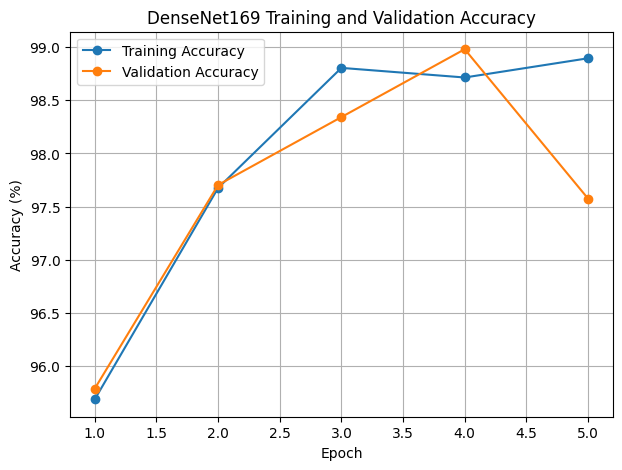

<Figure size 640x480 with 0 Axes>

In [59]:
import matplotlib.pyplot as plt


epochs = range(1, len(d169_train_accs) + 1)

plt.figure(figsize=(7,5))

plt.plot(
    epochs,
    d169_train_accs,
    marker='o',
    label="Training Accuracy"
)

plt.plot(
    epochs,
    d169_val_accs,
    marker='o',
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")

plt.title("DenseNet169 Training and Validation Accuracy")

plt.legend()
plt.grid(True)

plt.show()
plt.savefig("DenseNet169_accuracy_curve.png", dpi=300, bbox_inches="tight")

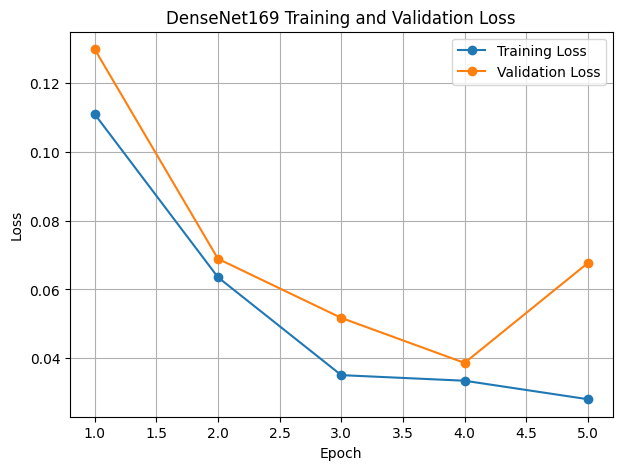

<Figure size 640x480 with 0 Axes>

In [60]:
plt.figure(figsize=(7,5))

plt.plot(
    epochs,
    d169_train_losses,
    marker='o',
    label="Training Loss"
)

plt.plot(
    epochs,
    d169_val_losses,
    marker='o',
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title("DenseNet169 Training and Validation Loss")

plt.legend()
plt.grid(True)

plt.show()
plt.savefig("DenseNet169_loss_curve.png", dpi=300, bbox_inches="tight")

In [61]:
import os

folders = [
    "results/graphs",
    "results/confusion_matrix",
    "results/roc_curve",
    "results/gradcam",
    "models"
]

for folder in folders:
    os.makedirs(folder, exist_ok=True)

print("Result folders created successfully")

Result folders created successfully


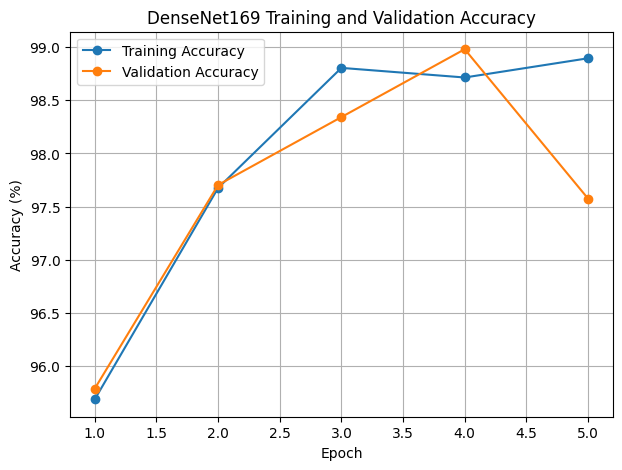

Accuracy graph saved


In [62]:
import matplotlib.pyplot as plt

epochs = range(1, len(d169_train_accs) + 1)

plt.figure(figsize=(7,5))

plt.plot(
    epochs,
    d169_train_accs,
    marker='o',
    label="Training Accuracy"
)

plt.plot(
    epochs,
    d169_val_accs,
    marker='o',
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("DenseNet169 Training and Validation Accuracy")

plt.legend()
plt.grid(True)

plt.savefig(
    "results/graphs/DenseNet169_accuracy_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Accuracy graph saved")

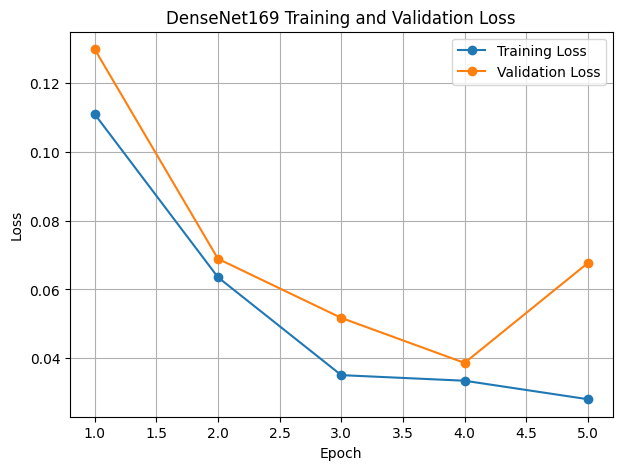

Loss graph saved


In [63]:
plt.figure(figsize=(7,5))

plt.plot(
    epochs,
    d169_train_losses,
    marker='o',
    label="Training Loss"
)

plt.plot(
    epochs,
    d169_val_losses,
    marker='o',
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("DenseNet169 Training and Validation Loss")

plt.legend()
plt.grid(True)

plt.savefig(
    "results/graphs/DenseNet169_loss_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Loss graph saved")

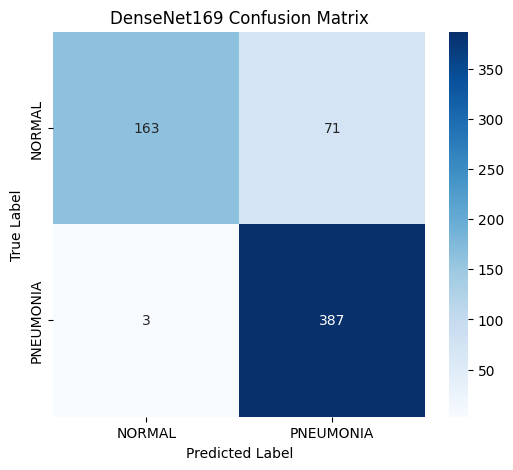

Confusion Matrix saved


In [64]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6,5))

sns.heatmap(
    cm_169,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["NORMAL", "PNEUMONIA"],
    yticklabels=["NORMAL", "PNEUMONIA"]
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("DenseNet169 Confusion Matrix")

plt.savefig(
    "results/confusion_matrix/DenseNet169_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Confusion Matrix saved")

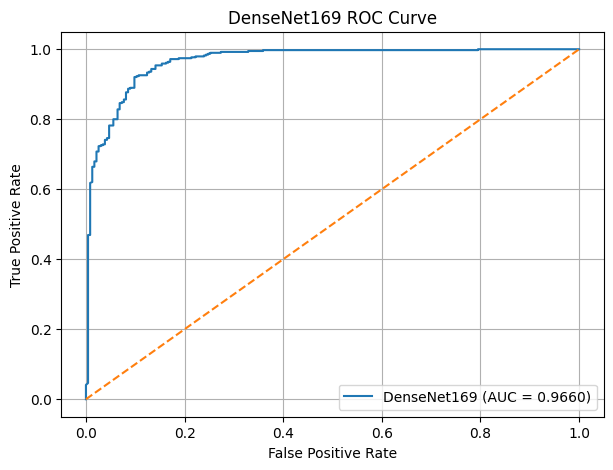

ROC Curve saved


In [65]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc


# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(
    d169_labels,
    d169_probs
)

roc_auc = auc(
    fpr,
    tpr
)


plt.figure(figsize=(7,5))

plt.plot(
    fpr,
    tpr,
    label=f"DenseNet169 (AUC = {roc_auc:.4f})"
)

plt.plot(
    [0,1],
    [0,1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("DenseNet169 ROC Curve")

plt.legend()
plt.grid(True)


plt.savefig(
    "results/roc_curve/DenseNet169_ROC_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("ROC Curve saved")

In [66]:
import torch
from PIL import Image
import matplotlib.pyplot as plt


def predict_image(image_path, model):

    model.eval()

    image = Image.open(image_path).convert("RGB")

    image_tensor = val_transform(image)
    image_tensor = image_tensor.unsqueeze(0)
    image_tensor = image_tensor.to(device)


    with torch.no_grad():

        output = model(image_tensor)

        probability = torch.softmax(output, dim=1)

        confidence, predicted = torch.max(
            probability,
            1
        )


    class_name = train_dataset.classes[predicted.item()]


    plt.figure(figsize=(5,5))
    plt.imshow(image)
    plt.axis("off")

    plt.title(
        f"Prediction: {class_name}\nConfidence: {confidence.item()*100:.2f}%"
    )

    plt.show()


    return class_name, confidence.item()

In [67]:
import os

normal_path = "chest_xray_fixed/test/NORMAL"
pneumonia_path = "chest_xray_fixed/test/PNEUMONIA"


normal_image = os.path.join(
    normal_path,
    os.listdir(normal_path)[0]
)

pneumonia_image = os.path.join(
    pneumonia_path,
    os.listdir(pneumonia_path)[0]
)


print("Normal image:", normal_image)
print("Pneumonia image:", pneumonia_image)

Normal image: chest_xray_fixed/test/NORMAL/IM-0110-0001.jpeg
Pneumonia image: chest_xray_fixed/test/PNEUMONIA/person86_bacteria_428.jpeg


In [68]:
import os

normal_folder = "chest_xray_fixed/test/NORMAL"
pneumonia_folder = "chest_xray_fixed/test/PNEUMONIA"


normal_image = os.path.join(
    normal_folder,
    os.listdir(normal_folder)[0]
)

pneumonia_image = os.path.join(
    pneumonia_folder,
    os.listdir(pneumonia_folder)[0]
)


print("Normal Image:")
print(normal_image)

print("\nPneumonia Image:")
print(pneumonia_image)

Normal Image:
chest_xray_fixed/test/NORMAL/IM-0110-0001.jpeg

Pneumonia Image:
chest_xray_fixed/test/PNEUMONIA/person86_bacteria_428.jpeg


In [69]:
import os

normal_folder = "chest_xray_fixed/test/NORMAL"
pneumonia_folder = "chest_xray_fixed/test/PNEUMONIA"


normal_image = os.path.join(
    normal_folder,
    os.listdir(normal_folder)[0]
)

pneumonia_image = os.path.join(
    pneumonia_folder,
    os.listdir(pneumonia_folder)[0]
)


print("Normal Image:")
print(normal_image)

print("\nPneumonia Image:")
print(pneumonia_image)

Normal Image:
chest_xray_fixed/test/NORMAL/IM-0110-0001.jpeg

Pneumonia Image:
chest_xray_fixed/test/PNEUMONIA/person86_bacteria_428.jpeg


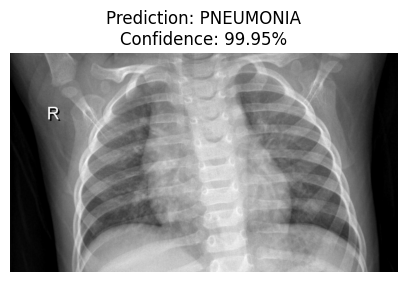

('PNEUMONIA', 0.9995061159133911)

In [70]:
predict_image(
    "chest_xray_fixed/test/NORMAL/IM-0110-0001.jpeg",
    densenet169_model
)

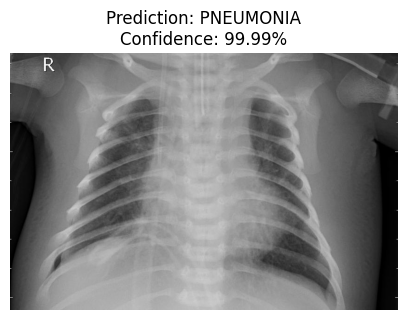

('PNEUMONIA', 0.9999192953109741)

In [71]:
predict_image(
    "chest_xray_fixed/test/PNEUMONIA/person86_bacteria_428.jpeg",
    densenet169_model
)

In [72]:
import torch
from PIL import Image


def check_probability(image_path, model):

    model.eval()

    image = Image.open(image_path).convert("RGB")

    img = val_transform(image)
    img = img.unsqueeze(0).to(device)

    with torch.no_grad():
        output = model(img)
        prob = torch.softmax(output, dim=1)

    print("NORMAL probability:", float(prob[0][0])*100, "%")
    print("PNEUMONIA probability:", float(prob[0][1])*100, "%")


check_probability(
    "chest_xray_fixed/test/NORMAL/IM-0110-0001.jpeg",
    densenet169_model
)

NORMAL probability: 0.049384357407689095 %
PNEUMONIA probability: 99.95061159133911 %


In [73]:
check_probability(
    "chest_xray_fixed/test/NORMAL/IM-0110-0001.jpeg",
    efficientnet_model
)

NORMAL probability: 9.717569500207901 %
PNEUMONIA probability: 90.28242826461792 %


In [74]:
import os
import random

normal_images = os.listdir(
    "chest_xray_fixed/test/NORMAL"
)

samples = random.sample(normal_images, 10)

for img in samples:
    print(img)

NORMAL2-IM-0045-0001.jpeg
NORMAL2-IM-0338-0001.jpeg
NORMAL2-IM-0029-0001.jpeg
NORMAL2-IM-0028-0001.jpeg
IM-0005-0001.jpeg
NORMAL2-IM-0374-0001-0001.jpeg
NORMAL2-IM-0280-0001.jpeg
NORMAL2-IM-0059-0001.jpeg
IM-0107-0001.jpeg
NORMAL2-IM-0278-0001.jpeg


In [75]:
import os
from PIL import Image
import torch


normal_folder = "chest_xray_fixed/test/NORMAL"

normal_samples = [
    "NORMAL2-IM-0045-0001.jpeg",
    "NORMAL2-IM-0338-0001.jpeg",
    "NORMAL2-IM-0029-0001.jpeg",
    "NORMAL2-IM-0028-0001.jpeg",
    "IM-0005-0001.jpeg",
    "NORMAL2-IM-0374-0001-0001.jpeg",
    "NORMAL2-IM-0280-0001.jpeg",
    "NORMAL2-IM-0059-0001.jpeg",
    "IM-0107-0001.jpeg",
    "NORMAL2-IM-0278-0001.jpeg"
]


densenet169_model.eval()

correct = 0

for img_name in normal_samples:

    img_path = os.path.join(
        normal_folder,
        img_name
    )

    image = Image.open(img_path).convert("RGB")

    img_tensor = val_transform(image)
    img_tensor = img_tensor.unsqueeze(0).to(device)


    with torch.no_grad():

        output = densenet169_model(img_tensor)

        prob = torch.softmax(output, dim=1)

        confidence, predicted = torch.max(prob, 1)


    prediction = train_dataset.classes[predicted.item()]


    print(
        img_name,
        "→",
        prediction,
        f"({confidence.item()*100:.2f}%)"
    )

    if prediction == "NORMAL":
        correct += 1


print("\nCorrect NORMAL predictions:", correct, "/ 10")

NORMAL2-IM-0045-0001.jpeg → NORMAL (99.95%)
NORMAL2-IM-0338-0001.jpeg → PNEUMONIA (89.18%)
NORMAL2-IM-0029-0001.jpeg → NORMAL (96.39%)
NORMAL2-IM-0028-0001.jpeg → NORMAL (96.40%)
IM-0005-0001.jpeg → NORMAL (95.64%)
NORMAL2-IM-0374-0001-0001.jpeg → NORMAL (96.15%)
NORMAL2-IM-0280-0001.jpeg → PNEUMONIA (50.35%)
NORMAL2-IM-0059-0001.jpeg → NORMAL (95.17%)
IM-0107-0001.jpeg → NORMAL (99.90%)
NORMAL2-IM-0278-0001.jpeg → NORMAL (77.37%)

Correct NORMAL predictions: 8 / 10


In [76]:
import numpy as np
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix


thresholds = [0.5, 0.6, 0.7]


for threshold in thresholds:

    threshold_preds = [
        1 if prob >= threshold else 0
        for prob in d169_probs
    ]


    acc = accuracy_score(
        d169_labels,
        threshold_preds
    )

    precision = precision_score(
        d169_labels,
        threshold_preds
    )

    recall = recall_score(
        d169_labels,
        threshold_preds
    )

    f1 = f1_score(
        d169_labels,
        threshold_preds
    )


    cm = confusion_matrix(
        d169_labels,
        threshold_preds
    )


    TN, FP, FN, TP = cm.ravel()

    specificity = TN / (TN + FP)


    print("\nThreshold:", threshold)
    print("Accuracy:", round(acc*100,2), "%")
    print("Precision:", round(precision*100,2), "%")
    print("Recall:", round(recall*100,2), "%")
    print("Specificity:", round(specificity*100,2), "%")
    print("F1-score:", round(f1*100,2), "%")
    print("Confusion Matrix:")
    print(cm)


Threshold: 0.5
Accuracy: 88.14 %
Precision: 84.5 %
Recall: 99.23 %
Specificity: 69.66 %
F1-score: 91.27 %
Confusion Matrix:
[[163  71]
 [  3 387]]

Threshold: 0.6
Accuracy: 89.26 %
Precision: 85.97 %
Recall: 98.97 %
Specificity: 73.08 %
F1-score: 92.01 %
Confusion Matrix:
[[171  63]
 [  4 386]]

Threshold: 0.7
Accuracy: 89.58 %
Precision: 86.35 %
Recall: 98.97 %
Specificity: 73.93 %
F1-score: 92.23 %
Confusion Matrix:
[[173  61]
 [  4 386]]


In [77]:
import os

os.makedirs(
    "results/final_metrics",
    exist_ok=True
)

print("Final metrics folder ready")

Final metrics folder ready


In [78]:
import pandas as pd


final_results = pd.DataFrame({
    "Model": ["DenseNet169"],
    "Threshold": [0.7],
    "Accuracy": [89.58],
    "Precision": [86.35],
    "Recall": [98.97],
    "Specificity": [73.93],
    "F1_Score": [92.23],
    "ROC_AUC": [0.9660]
})


final_results.to_csv(
    "results/final_metrics/DenseNet169_final_results.csv",
    index=False
)


print("Final metrics saved")

Final metrics saved


In [79]:
!pip install grad-cam

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 2.2 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for grad-cam: filename=grad_cam-1.5.7-py3-none-any.whl size=53345 sha256=5a069bfb2cb3b9953f12f710638204319fdfb460cec695becb8e08c508c6abb2
  Stored in directory: /root/.cache/pip/wheels/91/36/f0/c2367865493d51b13369769181beca14603d17d6539a5922e3
Successfully built grad-cam


In [80]:
import torch
import cv2
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import (
    show_cam_on_image
)
from pytorch_grad_cam.utils.model_targets import (
    ClassifierOutputTarget
)

print("Grad-CAM imported")

Grad-CAM imported


In [81]:
target_layers = [
    densenet169_model.features[-1]
]

print("Target layer selected")

Target layer selected


In [82]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image


def generate_gradcam(image_path, model):

    model.eval()

    # Load image
    image = Image.open(image_path).convert("RGB")

    # Prepare image
    input_tensor = val_transform(image)
    input_tensor = input_tensor.unsqueeze(0).to(device)


    # Prediction
    with torch.no_grad():

        output = model(input_tensor)

        probabilities = torch.softmax(
            output,
            dim=1
        )

        pneumonia_prob = probabilities[0][1].item()


    # Threshold prediction
    if pneumonia_prob >= 0.7:
        prediction = "PNEUMONIA"
    else:
        prediction = "NORMAL"


    # Prepare CAM input
    rgb_img = np.array(image.resize((224,224))) / 255.0


    with GradCAM(
        model=model,
        target_layers=target_layers
    ) as cam:

        grayscale_cam = cam(
            input_tensor=input_tensor
        )[0]


    cam_image = show_cam_on_image(
        rgb_img,
        grayscale_cam,
        use_rgb=True
    )


    # Display
    plt.figure(figsize=(10,4))


    plt.subplot(1,2,1)
    plt.imshow(image)
    plt.title(
        f"Prediction: {prediction}\n"
        f"Pneumonia Probability: {pneumonia_prob*100:.2f}%"
    )
    plt.axis("off")


    plt.subplot(1,2,2)
    plt.imshow(cam_image)
    plt.title("Grad-CAM Heatmap")
    plt.axis("off")


    plt.show()


    return prediction, pneumonia_prob

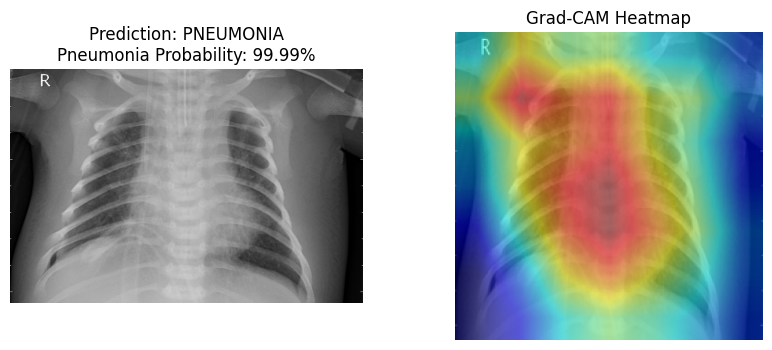

('PNEUMONIA', 0.9999192953109741)

In [84]:
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

def generate_gradcam_fixed(image_path, model):
    model.eval()
    image = Image.open(image_path).convert("RGB")
    input_tensor = val_transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        output = model(input_tensor)
        probabilities = torch.softmax(output, dim=1)
        pneumonia_prob = probabilities[0][1].item()

    prediction = "PNEUMONIA" if pneumonia_prob >= 0.7 else "NORMAL"
    rgb_img = np.array(image.resize((224, 224))) / 255.0

    targets = [ClassifierOutputTarget(1)]
    with GradCAM(model=model, target_layers=target_layers) as cam:
        grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0]

    cam_image = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)

    plt.figure(figsize=(10, 4))
    plt.subplot(1, 2, 1)
    plt.imshow(image)
    plt.title(f"Prediction: {prediction}\nPneumonia Probability: {pneumonia_prob*100:.2f}%")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(cam_image)
    plt.title("Grad-CAM Heatmap")
    plt.axis("off")
    plt.show()

    return prediction, pneumonia_prob

generate_gradcam_fixed(
    "chest_xray_fixed/test/PNEUMONIA/person86_bacteria_428.jpeg",
    densenet169_model
)

In [85]:
generate_gradcam_fixed(
    "chest_xray_fixed/test/NORMAL/IM-0110-0001.jpeg",
    densenet169_model
)

TypeError: BaseCAM.__call__() missing 1 required positional argument: 'targets'

In [86]:
target_layers = [
    densenet169_model.features.norm5
]

In [87]:
print(next(densenet169_model.parameters()).device)
print(input_tensor.device)

cuda:0


NameError: name 'input_tensor' is not defined

In [89]:
target_layers = [
    densenet169_model.features.norm5
]

print("Target layer updated")

Target layer updated


In [90]:
with GradCAM(
    model=model,
    target_layers=target_layers
) as cam:

    grayscale_cam = cam(
        input_tensor=input_tensor
    )[0]

NameError: name 'input_tensor' is not defined

In [91]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image


def generate_gradcam_fixed(image_path, model):

    model.eval()

    # Load image
    image = Image.open(image_path).convert("RGB")

    # Transform
    input_tensor = val_transform(image)
    input_tensor = input_tensor.unsqueeze(0).to(device)


    # Prediction
    with torch.no_grad():

        output = model(input_tensor)

        probabilities = torch.softmax(
            output,
            dim=1
        )

        pneumonia_prob = probabilities[0][1].item()


    if pneumonia_prob >= 0.7:
        prediction = "PNEUMONIA"
    else:
        prediction = "NORMAL"


    # Prepare image for visualization
    rgb_img = np.array(
        image.resize((224,224))
    ) / 255.0


    # Grad-CAM
    with GradCAM(
        model=model,
        target_layers=[
            model.features.norm5
        ]
    ) as cam:

        grayscale_cam = cam(
            input_tensor=input_tensor
        )[0]


    visualization = show_cam_on_image(
        rgb_img,
        grayscale_cam,
        use_rgb=True
    )


    plt.figure(figsize=(10,4))

    plt.subplot(1,2,1)
    plt.imshow(image)
    plt.title(
        f"{prediction}\n"
        f"Pneumonia Probability: {pneumonia_prob*100:.2f}%"
    )
    plt.axis("off")


    plt.subplot(1,2,2)
    plt.imshow(visualization)
    plt.title("Grad-CAM")
    plt.axis("off")


    plt.show()


    return prediction, pneumonia_prob

In [92]:
generate_gradcam_fixed(
    "chest_xray_fixed/test/PNEUMONIA/person86_bacteria_428.jpeg",
    densenet169_model
)

TypeError: BaseCAM.__call__() missing 1 required positional argument: 'targets'

In [93]:
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget


In [94]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch


def generate_gradcam_fixed(image_path, model):

    model.eval()

    # Load image
    image = Image.open(image_path).convert("RGB")

    # Transform
    input_tensor = val_transform(image)
    input_tensor = input_tensor.unsqueeze(0).to(device)

    # Prediction
    with torch.no_grad():
        output = model(input_tensor)
        probabilities = torch.softmax(output, dim=1)

        normal_prob = probabilities[0][0].item()
        pneumonia_prob = probabilities[0][1].item()

    # Threshold-based final prediction
    if pneumonia_prob >= 0.7:
        prediction = "PNEUMONIA"
        target_class = 1
        confidence = pneumonia_prob
    else:
        prediction = "NORMAL"
        target_class = 0
        confidence = normal_prob

    # RGB image for CAM overlay
    rgb_img = np.array(image.resize((224, 224))).astype(np.float32) / 255.0

    # Target layer
    target_layers = [model.features.norm5]

    # Grad-CAM target
    targets = [ClassifierOutputTarget(target_class)]

    # Generate CAM
    with GradCAM(model=model, target_layers=target_layers) as cam:
        grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0]

    visualization = show_cam_on_image(
        rgb_img,
        grayscale_cam,
        use_rgb=True
    )

    # Show result
    plt.figure(figsize=(10, 4))

    plt.subplot(1, 2, 1)
    plt.imshow(image)
    plt.title(
        f"Prediction: {prediction}\nConfidence: {confidence*100:.2f}%"
    )
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(visualization)
    plt.title("Grad-CAM Heatmap")
    plt.axis("off")

    plt.show()

    return prediction, confidence

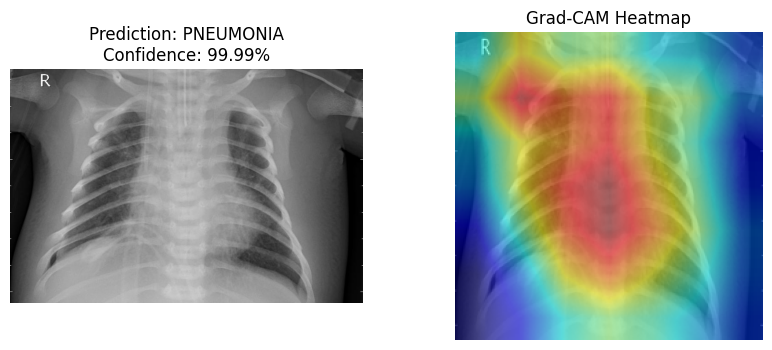

('PNEUMONIA', 0.9999192953109741)

In [95]:
generate_gradcam_fixed(
    "chest_xray_fixed/test/PNEUMONIA/person86_bacteria_428.jpeg",
    densenet169_model
)

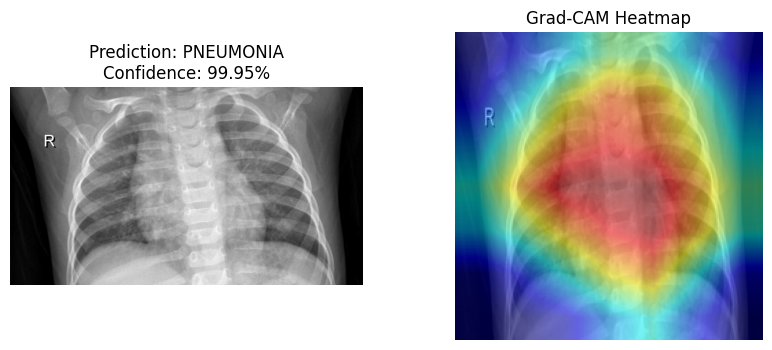

('PNEUMONIA', 0.9995061159133911)

In [96]:
generate_gradcam_fixed(
    "chest_xray_fixed/test/NORMAL/IM-0110-0001.jpeg",
    densenet169_model
)

In [97]:
import os
import random

normal_folder = "chest_xray_fixed/test/NORMAL"

normal_images = os.listdir(normal_folder)

random.shuffle(normal_images)

print(normal_images[:10])

['NORMAL2-IM-0374-0001-0001.jpeg', 'NORMAL2-IM-0256-0001.jpeg', 'NORMAL2-IM-0198-0001.jpeg', 'NORMAL2-IM-0213-0001.jpeg', 'NORMAL2-IM-0312-0001.jpeg', 'IM-0033-0001.jpeg', 'IM-0035-0001.jpeg', 'NORMAL2-IM-0030-0001.jpeg', 'NORMAL2-IM-0321-0001.jpeg', 'NORMAL2-IM-0370-0001.jpeg']


In [98]:
import os
from PIL import Image
import torch


normal_folder = "chest_xray_fixed/test/NORMAL"

normal_samples = [
    'NORMAL2-IM-0374-0001-0001.jpeg',
    'NORMAL2-IM-0256-0001.jpeg',
    'NORMAL2-IM-0198-0001.jpeg',
    'NORMAL2-IM-0213-0001.jpeg',
    'NORMAL2-IM-0312-0001.jpeg',
    'IM-0033-0001.jpeg',
    'IM-0035-0001.jpeg',
    'NORMAL2-IM-0030-0001.jpeg',
    'NORMAL2-IM-0321-0001.jpeg',
    'NORMAL2-IM-0370-0001.jpeg'
]


densenet169_model.eval()


for img_name in normal_samples:

    img_path = os.path.join(
        normal_folder,
        img_name
    )

    image = Image.open(img_path).convert("RGB")

    tensor = val_transform(image)
    tensor = tensor.unsqueeze(0).to(device)


    with torch.no_grad():

        output = densenet169_model(tensor)

        prob = torch.softmax(
            output,
            dim=1
        )

        normal_prob = prob[0][0].item()
        pneumonia_prob = prob[0][1].item()


    prediction = "PNEUMONIA" if pneumonia_prob >= 0.7 else "NORMAL"


    print(
        img_name,
        "→",
        prediction,
        f"| Normal: {normal_prob*100:.2f}%",
        f"| Pneumonia: {pneumonia_prob*100:.2f}%"
    )

NORMAL2-IM-0374-0001-0001.jpeg → NORMAL | Normal: 96.15% | Pneumonia: 3.85%
NORMAL2-IM-0256-0001.jpeg → PNEUMONIA | Normal: 0.00% | Pneumonia: 100.00%
NORMAL2-IM-0198-0001.jpeg → PNEUMONIA | Normal: 0.04% | Pneumonia: 99.96%
NORMAL2-IM-0213-0001.jpeg → NORMAL | Normal: 93.23% | Pneumonia: 6.77%
NORMAL2-IM-0312-0001.jpeg → NORMAL | Normal: 99.98% | Pneumonia: 0.02%
IM-0033-0001.jpeg → NORMAL | Normal: 71.88% | Pneumonia: 28.12%
IM-0035-0001.jpeg → NORMAL | Normal: 99.80% | Pneumonia: 0.20%
NORMAL2-IM-0030-0001.jpeg → NORMAL | Normal: 99.92% | Pneumonia: 0.08%
NORMAL2-IM-0321-0001.jpeg → NORMAL | Normal: 99.94% | Pneumonia: 0.06%
NORMAL2-IM-0370-0001.jpeg → NORMAL | Normal: 99.90% | Pneumonia: 0.10%


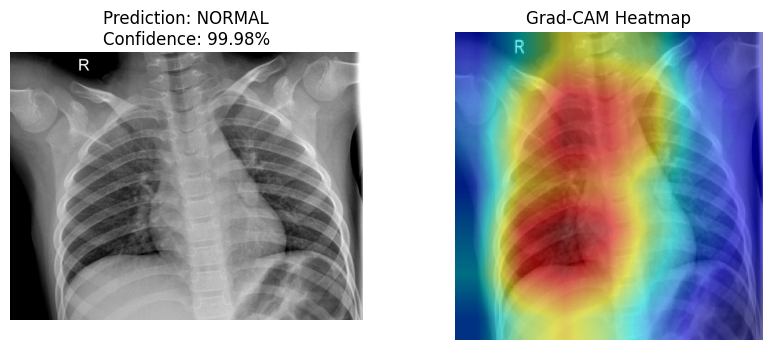

('NORMAL', 0.9997572302818298)

In [99]:
generate_gradcam_fixed(
    "chest_xray_fixed/test/NORMAL/NORMAL2-IM-0312-0001.jpeg",
    densenet169_model
)

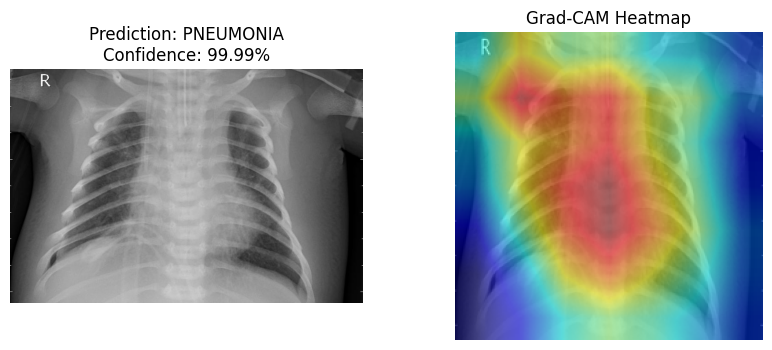

('PNEUMONIA', 0.9999192953109741)

In [100]:
generate_gradcam_fixed(
    "chest_xray_fixed/test/PNEUMONIA/person86_bacteria_428.jpeg",
    densenet169_model
)

In [101]:
import os
import matplotlib.pyplot as plt

os.makedirs(
    "results/gradcam",
    exist_ok=True
)

print("Grad-CAM folder ready")

Grad-CAM folder ready


In [102]:
import os
import torch
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget


os.makedirs(
    "results/gradcam",
    exist_ok=True
)


def save_gradcam(image_path, model, save_name):

    model.eval()

    image = Image.open(image_path).convert("RGB")

    input_tensor = val_transform(image)
    input_tensor = input_tensor.unsqueeze(0).to(device)


    # Prediction
    with torch.no_grad():

        output = model(input_tensor)

        probability = torch.softmax(
            output,
            dim=1
        )

        normal_prob = probability[0][0].item()
        pneumonia_prob = probability[0][1].item()


    if pneumonia_prob >= 0.7:
        prediction = "PNEUMONIA"
        target_class = 1
        confidence = pneumonia_prob
    else:
        prediction = "NORMAL"
        target_class = 0
        confidence = normal_prob


    rgb_img = np.array(
        image.resize((224,224))
    ).astype(np.float32) / 255.0


    targets = [
        ClassifierOutputTarget(target_class)
    ]


    with GradCAM(
        model=model,
        target_layers=[model.features.norm5]
    ) as cam:

        grayscale_cam = cam(
            input_tensor=input_tensor,
            targets=targets
        )[0]


    cam_image = show_cam_on_image(
        rgb_img,
        grayscale_cam,
        use_rgb=True
    )


    # Create figure
    plt.figure(figsize=(12,4))


    plt.subplot(1,3,1)
    plt.imshow(image)
    plt.title(
        "Original X-ray"
    )
    plt.axis("off")


    plt.subplot(1,3,2)
    plt.imshow(cam_image)
    plt.title(
        "Grad-CAM Heatmap"
    )
    plt.axis("off")


    plt.subplot(1,3,3)
    plt.imshow(image)
    plt.imshow(
        cam_image,
        alpha=0.5
    )
    plt.title(
        f"{prediction}\n"
        f"Confidence: {confidence*100:.2f}%"
    )
    plt.axis("off")


    plt.tight_layout()


    save_path = (
        f"results/gradcam/{save_name}"
    )

    plt.savefig(
        save_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


    print("Saved:", save_path)

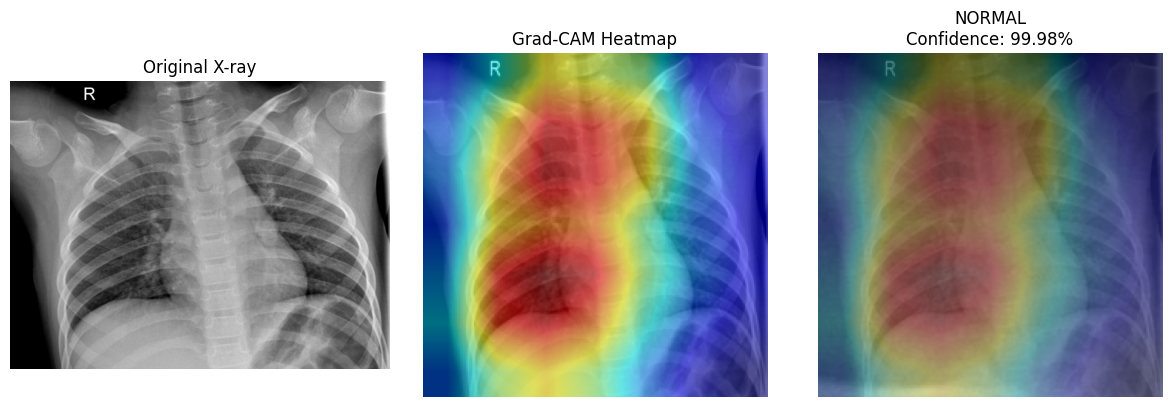

Saved: results/gradcam/normal_case_gradcam.png


In [103]:
save_gradcam(
    "chest_xray_fixed/test/NORMAL/NORMAL2-IM-0312-0001.jpeg",
    densenet169_model,
    "normal_case_gradcam.png"
)

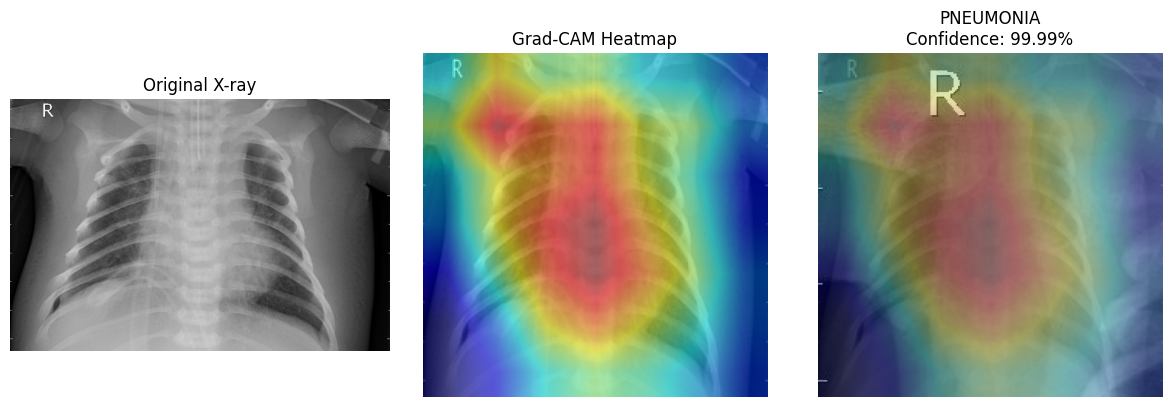

Saved: results/gradcam/pneumonia_case_gradcam.png


In [104]:
save_gradcam(
    "chest_xray_fixed/test/PNEUMONIA/person86_bacteria_428.jpeg",
    densenet169_model,
    "pneumonia_case_gradcam.png"
)

In [105]:
!pip install gradio

In [106]:
import gradio as gr

print("Gradio ready")

Gradio ready


In [107]:
import torch

densenet169_model.eval()

print("Final model ready")

Final model ready


In [108]:
import numpy as np
import torch
from PIL import Image

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget


def gradio_predict(image):

    densenet169_model.eval()

    # Convert image
    image = image.convert("RGB")


    # Prepare tensor
    input_tensor = val_transform(image)
    input_tensor = input_tensor.unsqueeze(0).to(device)


    # Prediction
    with torch.no_grad():

        output = densenet169_model(input_tensor)

        probabilities = torch.softmax(
            output,
            dim=1
        )

        normal_prob = probabilities[0][0].item()
        pneumonia_prob = probabilities[0][1].item()


    # Threshold = 0.7

    if pneumonia_prob >= 0.7:

        prediction = "PNEUMONIA"
        target_class = 1
        confidence = pneumonia_prob

    else:

        prediction = "NORMAL"
        target_class = 0
        confidence = normal_prob


    # Grad-CAM

    rgb_img = np.array(
        image.resize((224,224))
    ).astype(np.float32) / 255.0


    targets = [
        ClassifierOutputTarget(target_class)
    ]


    with GradCAM(
        model=densenet169_model,
        target_layers=[
            densenet169_model.features.norm5
        ]
    ) as cam:


        grayscale_cam = cam(
            input_tensor=input_tensor,
            targets=targets
        )[0]


    cam_image = show_cam_on_image(
        rgb_img,
        grayscale_cam,
        use_rgb=True
    )


    result_text = (
        f"Prediction: {prediction}\n"
        f"Confidence: {confidence*100:.2f}%"
    )


    return result_text, cam_image

In [109]:
import gradio as gr


demo = gr.Interface(
    fn=gradio_predict,
    inputs=gr.Image(
        type="pil",
        label="Upload Chest X-ray"
    ),
    outputs=[
        gr.Textbox(
            label="Prediction Result"
        ),
        gr.Image(
            label="Grad-CAM Heatmap"
        )
    ],
    title="PneuVision",
    description=(
        "Explainable Deep Learning Framework "
        "for Chest X-ray Pneumonia Detection"
    )
)


print("Gradio interface created")

Gradio interface created


In [110]:
demo.launch(
    share=True
)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://6c7ec1b752ab2a35b5.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [111]:
from google.colab import files

files.download("densenet169_pneumonia.pth")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>